In [3]:
import os
import keras
from keras.utils import image_dataset_from_directory

keras.utils.set_random_seed(42)

dataset_dir = os.path.join("..","data","aircraft_damage_dataset_v1")
IMG_SIZE = (224,224)
BATCH_SIZE = 32

In [4]:
train_ds = image_dataset_from_directory(os.path.join(dataset_dir ,"train"),
                                        label_mode = "binary",
                                        image_size = IMG_SIZE,
                                        batch_size = BATCH_SIZE,
                                        shuffle = True,
                                        seed = 42,)
print(train_ds.class_names)

Found 300 files belonging to 2 classes.


['crack', 'dent']


In [5]:
valid_ds = image_dataset_from_directory(os.path.join(dataset_dir,"valid"),
                                        label_mode = "binary",
                                        image_size = IMG_SIZE,
                                        batch_size = BATCH_SIZE,
                                        shuffle = False,
                                        seed = 42,)
print(valid_ds.class_names)

Found 96 files belonging to 2 classes.
['crack', 'dent']


In [6]:
test_ds = image_dataset_from_directory(os.path.join(dataset_dir,"test"),
                                        label_mode = "binary",
                                        image_size = IMG_SIZE,
                                        batch_size = BATCH_SIZE,
                                        shuffle = False,
                                        seed = 42,)
print(test_ds.class_names)

Found 50 files belonging to 2 classes.
['crack', 'dent']


In [7]:
images,labels = next(iter(train_ds))

print("Images Shape:",images.shape )
print("Labels Shape:",labels.shape )
print("Pixel min / max:",float(images.numpy().min()),float(images.numpy().max()))
print("first 8 labels: ", labels.numpy()[:8].ravel())
print("number of batches:",len(train_ds))

Images Shape: (32, 224, 224, 3)
Labels Shape: (32, 1)
Pixel min / max: 0.0 255.0
first 8 labels:  [0. 0. 1. 0. 0. 0. 1. 0.]
number of batches: 10


In [8]:
from keras.applications.vgg16 import VGG16,preprocess_input 
from keras import layers,models,optimizers 

In [9]:
base_model = VGG16( 
                   weights = 'imagenet',
                   include_top = False,
                   input_shape = (224,224,3),
                   )
base_model.trainable = False

In [10]:
inputs = layers.Input(shape=(224,224,3))
x = preprocess_input(inputs)
x= base_model(x,training = False)
x = layers.Flatten()(x)
x = layers.Dense(256,activation = "relu")(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(1, activation = "sigmoid")(x) 
model  = models.Model(inputs,outputs)

In [11]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ input_layer_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ input_layer_2[0]… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ input_layer_2[0]… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vgg16 (Functional)  │ (None, 7, 7, 512) │ 14,714,688 │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 25088)     │          0 │ vgg16[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │  6,422,784 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 256)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 1)         │        257 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 21,137,729 (80.63 MB)

 Trainable params: 6,423,041 (24.50 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [12]:
model.compile(
    optimizer = optimizers.Adam(learning_rate = 1e-4),
    loss = "binary_crossentropy",
    metrics = ["accuracy", keras.metrics.Recall(name ="recall")]
)

In [13]:
history = model.fit(
    train_ds,
    validation_data = valid_ds,
    epochs = 5,
)

Epoch 1/5


c:\Users\sawwa\OneDrive\Desktop\aircraft-damage-classification-captioning\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


10/10 ━━━━━━━━━━━━━━━━━━━━ 40s 4s/step - accuracy: 0.6267 - loss: 4.2659 - recall: 0.6267 - val_accuracy: 0.6667 - val_loss: 3.2596 - val_recall: 0.6042
Epoch 2/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 37s 4s/step - accuracy: 0.8600 - loss: 1.0041 - recall: 0.8933 - val_accuracy: 0.6875 - val_loss: 2.5324 - val_recall: 0.7500
Epoch 3/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 36s 4s/step - accuracy: 0.9300 - loss: 0.6650 - recall: 0.9133 - val_accuracy: 0.6771 - val_loss: 2.6002 - val_recall: 0.7500
Epoch 4/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 37s 4s/step - accuracy: 0.9600 - loss: 0.1913 - recall: 0.9600 - val_accuracy: 0.6771 - val_loss: 3.0976 - val_recall: 0.7917
Epoch 5/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 37s 4s/step - accuracy: 0.9833 - loss: 0.0429 - recall: 0.9867 - val_accuracy: 0.6562 - val_loss: 3.5588 - val_recall: 0.8333


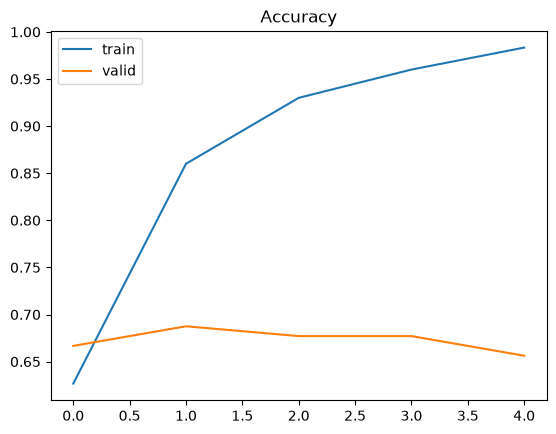

In [14]:
import matplotlib.pyplot as plt 

plt.plot(history.history["accuracy"],label = "train")
plt.plot(history.history["val_accuracy"],label = "valid")
plt.legend()
plt.title("Accuracy")
plt.show()


The model was overfitting. To fix that i gonna we two method -Early Stopping and Augmentation

In [15]:
from keras.callbacks import EarlyStopping

early = EarlyStopping(monitor = "val_loss", patience = 2, restore_best_weights = True)

history = model.fit(
    train_ds,
    validation_data = valid_ds,
    epochs = 20,
    callbacks =[early],
)


Epoch 1/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 37s 4s/step - accuracy: 0.9767 - loss: 0.1056 - recall: 0.9933 - val_accuracy: 0.7083 - val_loss: 2.7680 - val_recall: 0.7500
Epoch 2/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 35s 4s/step - accuracy: 0.9667 - loss: 0.1760 - recall: 0.9533 - val_accuracy: 0.8021 - val_loss: 2.6261 - val_recall: 0.7500
Epoch 3/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 38s 4s/step - accuracy: 0.9867 - loss: 0.1169 - recall: 0.9933 - val_accuracy: 0.6875 - val_loss: 3.9364 - val_recall: 0.8125
Epoch 4/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 37s 4s/step - accuracy: 0.9900 - loss: 0.0657 - recall: 1.0000 - val_accuracy: 0.7188 - val_loss: 3.6833 - val_recall: 0.8125


In [16]:
print("Best epoch:",early.stopped_epoch - early.patience +1)

Best epoch: 2


In [17]:
test_loss, test_acc, test_recall = model.evaluate(test_ds)
print(f"Test Accuracy: {test_acc:.3f}")
print(f"Test recall: {test_recall:.3f}")

2/2 ━━━━━━━━━━━━━━━━━━━━ 5s 2s/step - accuracy: 0.8400 - loss: 1.7221 - recall: 0.8800
Test Accuracy: 0.840
Test recall: 0.880


In [18]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report 

y_prob = model.predict(test_ds).ravel()
y_pred = (y_prob>0.5).astype(int)

y_true = np.concatenate([y.numpy().ravel() for x,y in test_ds])
print(confusion_matrix(y_true,y_pred))
print(classification_report(y_true,y_pred,target_names = ["crack","dent"]))

2/2 ━━━━━━━━━━━━━━━━━━━━ 5s 2s/step
[[20  5]
 [ 3 22]]
              precision    recall  f1-score   support

       crack       0.87      0.80      0.83        25
        dent       0.81      0.88      0.85        25

    accuracy                           0.84        50
   macro avg       0.84      0.84      0.84        50
weighted avg       0.84      0.84      0.84        50



In [19]:
for t in [0.7,0.6,0.5,0.4,0.3]:
    pred = (y_prob>t).astype(int)
    tp = ((pred == 1) & (y_true == 1)).sum()
    fp = ((pred == 1) & (y_true == 0)).sum() 
    tn = ((pred == 0) & (y_true == 0)).sum()
    fn = ((pred == 0) & (y_true == 1)).sum()
    print(f"Threshold: {t}")
    print(f"TP: {tp}, FP: {fp}, TN: {tn}, FN: {fn}")

Threshold: 0.7
TP: 21, FP: 4, TN: 21, FN: 4
Threshold: 0.6
TP: 21, FP: 4, TN: 21, FN: 4
Threshold: 0.5
TP: 22, FP: 5, TN: 20, FN: 3
Threshold: 0.4
TP: 22, FP: 6, TN: 19, FN: 3
Threshold: 0.3
TP: 22, FP: 7, TN: 18, FN: 3


In [20]:
import numpy as np

# crack = positive (label 0 ကို ကိုယ်ပိုင် positive အဖြစ် ပြောင်း)
# y_prob က dent ဖြစ်နိုင်ချေ → crack ဖြစ်နိုင်ချေ = 1 - y_prob
crack_score = 1 - y_prob
y_true_crack = (y_true == 0).astype(int)   # crack = 1, dent = 0

for t in [0.5, 0.6, 0.7, 0.8, 0.9]:
    pred_crack = (crack_score > t).astype(int)

    tp = ((pred_crack == 1) & (y_true_crack == 1)).sum()
    fp = ((pred_crack == 1) & (y_true_crack == 0)).sum()
    fn = ((pred_crack == 0) & (y_true_crack == 1)).sum()

    recall    = tp / (tp + fn) if (tp + fn) else 0
    precision = tp / (tp + fp) if (tp + fp) else 0

    print(f"threshold {t}: TP={tp} FP={fp} FN={fn} | crack recall={recall:.2f} precision={precision:.2f}")

threshold 0.5: TP=20 FP=3 FN=5 | crack recall=0.80 precision=0.87
threshold 0.6: TP=19 FP=3 FN=6 | crack recall=0.76 precision=0.86
threshold 0.7: TP=18 FP=3 FN=7 | crack recall=0.72 precision=0.86
threshold 0.8: TP=18 FP=3 FN=7 | crack recall=0.72 precision=0.86
threshold 0.9: TP=18 FP=2 FN=7 | crack recall=0.72 precision=0.90


In [21]:
import numpy as np

y_prob_val = model.predict(valid_ds).ravel()
y_true_val = np.concatenate([y.numpy().ravel() for x,y in valid_ds])
crack_score_val = 1 - y_prob_val
y_true_crack_val = (y_true_val ==0 ).astype(int)

for t in [0.2, 0.3,0.4 ,0.5]:
    pred_crack= (crack_score_val > t).astype(int)
    # TP = crack အမှန် + crack လို့ ခန့်မှန်း
    tp = ((pred_crack == 1) & (y_true_crack_val ==1)).sum()

    # FP = dent အမှန် + crack လို့ မှားခန့်မှန်း
    fp = ((pred_crack == 1) & (y_true_crack_val == 0)).sum()

    # FN = crack အမှန် + dent လို့ မှားခန့်မှန်း (😱 အန္တရာယ်ကြီး)
    fn = ((pred_crack == 0) & (y_true_crack_val == 1)).sum()
    recall    = tp / (tp + fn) if (tp + fn) else 0
    precision = tp / (tp + fp) if (tp + fp) else 0
    
    print(f"threshold {t}: TP={tp} FP={fp} FN={fn} | recall={recall:.2f} precision={precision:.2f}")

3/3 ━━━━━━━━━━━━━━━━━━━━ 9s 3s/step
threshold 0.2: TP=41 FP=12 FN=7 | recall=0.85 precision=0.77
threshold 0.3: TP=41 FP=12 FN=7 | recall=0.85 precision=0.77
threshold 0.4: TP=41 FP=12 FN=7 | recall=0.85 precision=0.77
threshold 0.5: TP=41 FP=12 FN=7 | recall=0.85 precision=0.77


In [22]:
print (np.round(np.sort(crack_score_val),3))

middle = ((crack_score_val > 0.2) & (crack_score_val < 0.5)).sum()
print("Between 0.2and 0.5: ",middle)

for t in [0.001,0.01,0.5,0.1]:
    pred_crack = (crack_score_val > t ).astype(int)
    tp = ((pred_crack == 1) & (y_true_crack_val == 1)).sum()
    fp = ((pred_crack == 1) & (y_true_crack_val == 0)).sum()
    fn = ((pred_crack == 0) & (y_true_crack_val == 1)).sum()
    
    recall = tp / (tp+fn) if (tp+fn) else 0 
    precision = tp / (tp+fp) if (tp+ fp ) else 0
    print(f"threshold {t}: TP={tp} FP={fp} FN={fn} | recall={recall:.2f} precision={precision:.2f}")

[0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.
 0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.
 0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.004
 0.006 0.007 0.012 0.015 0.027 0.065 0.078 0.511 0.512 0.521 0.618 0.695
 0.756 0.856 0.91  0.921 0.942 0.942 0.97  0.974 0.982 0.983 0.995 0.995
 0.996 0.997 1.    1.    1.    1.    1.    1.    1.    1.    1.    1.
 1.    1.    1.    1.    1.    1.    1.    1.    1.    1.    1.    1.
 1.    1.    1.    1.    1.    1.    1.    1.    1.    1.    1.    1.   ]
Between 0.2and 0.5:  0
threshold 0.001: TP=44 FP=17 FN=4 | recall=0.92 precision=0.72
threshold 0.01: TP=43 FP=15 FN=5 | recall=0.90 precision=0.74
threshold 0.5: TP=41 FP=12 FN=7 | recall=0.85 precision=0.77
threshold 0.1: TP=41 FP=12 FN=7 | recall=0.85 precision=0.77


### Threshold analysis (before augmentation, valid set)
- Model is overconfident: most crack scores are 0 or 1, none between 0.08 and 0.51
- t=0.5: crack recall 0.85, precision 0.77 (FN=7)
- t=0.01: crack recall 0.90, precision 0.74 (FN=5)
- Conclusion: fix overfitting with data augmentation, then re-tune threshold

In [23]:
from keras import layers

data_augmentation = keras.Sequential([
    layers.RandomFlip("Horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    
],name ="augmentation")

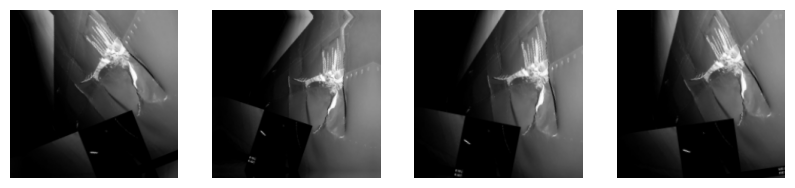

In [24]:
import matplotlib.pyplot as plt 

images, labels = next(iter(train_ds))
plt.figure(figsize=(10,4))
for i in range (4):
    aug = data_augmentation(images[:1],training = True)
    plt.subplot(1,4,i+1)
    plt.imshow(aug[0].numpy().astype("uint8"))
    plt.axis("off")
plt.show()

In [25]:
from keras.applications import VGG16
from keras.applications.vgg16 import preprocess_input
from keras import models, optimizers

base_model2 = VGG16(weights ="imagenet", include_top =False, input_shape=(224,224,3))
base_model2.trainable = False

inputs = keras.Input(shape=(224,224,3))
x = data_augmentation(inputs)
x = preprocess_input(x)
x = base_model2(x,training = False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(256,activation="relu")(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(1,activation="sigmoid")(x)

model2 = models.Model(inputs,outputs)
model2.compile(
    optimizer = optimizers.Adam(learning_rate=1e-4),
    loss ="binary_crossentropy",
    metrics = [ keras.metrics.BinaryAccuracy(name="accuracy"),   
        keras.metrics.Recall(name="recall"),],
)




In [26]:
from keras.callbacks import EarlyStopping 
early2 = EarlyStopping(monitor= "val_loss",patience=5,restore_best_weights=True)
history2 = model2.fit(train_ds, validation_data=valid_ds,epochs = 30,callbacks=[early2])

Epoch 1/30


c:\Users\sawwa\OneDrive\Desktop\aircraft-damage-classification-captioning\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


10/10 ━━━━━━━━━━━━━━━━━━━━ 40s 4s/step - accuracy: 0.5533 - loss: 1.6485 - recall: 0.6867 - val_accuracy: 0.6771 - val_loss: 0.9284 - val_recall: 0.7708
Epoch 2/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 39s 4s/step - accuracy: 0.5133 - loss: 1.5811 - recall: 0.5200 - val_accuracy: 0.6562 - val_loss: 0.9003 - val_recall: 0.7917
Epoch 3/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 39s 4s/step - accuracy: 0.5533 - loss: 1.4547 - recall: 0.6333 - val_accuracy: 0.6458 - val_loss: 0.9139 - val_recall: 0.7917
Epoch 4/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 39s 4s/step - accuracy: 0.5233 - loss: 1.4752 - recall: 0.5400 - val_accuracy: 0.6562 - val_loss: 0.8961 - val_recall: 0.8125
Epoch 5/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 40s 4s/step - accuracy: 0.5567 - loss: 1.4977 - recall: 0.6733 - val_accuracy: 0.6979 - val_loss: 0.8152 - val_recall: 0.7917
Epoch 6/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 40s 4s/step - accuracy: 0.5933 - loss: 1.1763 - recall: 0.6200 - val_accuracy: 0.7500 - val_loss: 0.7648 - val_recall: 0.7292
Epoch 7/30
10/10 ━━━━━━━━━━

In [27]:
model2.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_5       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ augmentation        │ (None, 224, 224,  │          0 │ input_layer_5[0]… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_3          │ (None, 224, 224)  │          0 │ augmentation[0][… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_4          │ (None, 224, 224)  │          0 │ augmentation[0][… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_5          │ (None, 224, 224)  │          0 │ augmentation[0][… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack_1 (Stack)     │ (None, 224, 224,  │          0 │ get_item_3[0][0], │
│                     │ 3)                │            │ get_item_4[0][0], │
│                     │                   │            │ get_item_5[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 224, 224,  │          0 │ stack_1[0][0]     │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vgg16 (Functional)  │ (None, 7, 7, 512) │ 14,714,688 │ add_1[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 512)       │          0 │ vgg16[0][0]       │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 256)       │    131,328 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 256)       │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 1)         │        257 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 15,109,445 (57.64 MB)

 Trainable params: 131,585 (514.00 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

 Optimizer params: 263,172 (1.00 MB)

In [28]:
model2.save("../models/model2_gap_aug_e30.keras")

model2.optimizer.learning_rate.assign(1e-3)
early3 = EarlyStopping(monitor="val_loss",patience=5,restore_best_weights=True)
histor3 = model2.fit(train_ds, validation_data = valid_ds, epochs = 20 , callbacks=[early3])

Epoch 1/20


c:\Users\sawwa\OneDrive\Desktop\aircraft-damage-classification-captioning\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


10/10 ━━━━━━━━━━━━━━━━━━━━ 37s 4s/step - accuracy: 0.7467 - loss: 0.5446 - recall: 0.7000 - val_accuracy: 0.8229 - val_loss: 0.6392 - val_recall: 0.9583
Epoch 2/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 37s 4s/step - accuracy: 0.8233 - loss: 0.4076 - recall: 0.8467 - val_accuracy: 0.7604 - val_loss: 0.6021 - val_recall: 0.7292
Epoch 3/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 37s 4s/step - accuracy: 0.8000 - loss: 0.4596 - recall: 0.7800 - val_accuracy: 0.7812 - val_loss: 0.7135 - val_recall: 0.9583
Epoch 4/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 36s 4s/step - accuracy: 0.8233 - loss: 0.3975 - recall: 0.8200 - val_accuracy: 0.8021 - val_loss: 0.5154 - val_recall: 0.8333
Epoch 5/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 37s 4s/step - accuracy: 0.8400 - loss: 0.3411 - recall: 0.8400 - val_accuracy: 0.7812 - val_loss: 0.5320 - val_recall: 0.8125
Epoch 6/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 37s 4s/step - accuracy: 0.8200 - loss: 0.3642 - recall: 0.8667 - val_accuracy: 0.7812 - val_loss: 0.5714 - val_recall: 0.6875
Epoch 7/20
10/10 ━━━━━━━━━━

In [30]:
model2.save("../models/model2_gap_aug_best.keras")
y_prob_val2 = model2.predict(valid_ds).ravel()
crack_score_val2 = 1 - y_prob_val2

print(np.round(np.sort(crack_score_val2),2))
middle = ((crack_score_val2 > 0.2) & (crack_score_val2 <0.8)).sum()
print("Between 0.2 and 0.8",middle)
for t in [0.2,0.3,0.4,0.5]:
    pred_crack = (crack_score_val2 > t ).astype(int)
    tp = ((pred_crack == 1) & (y_true_crack_val == 1)).sum()
    fp = ((pred_crack == 1) & (y_true_crack_val == 0)).sum()
    fn = ((pred_crack == 0) & (y_true_crack_val == 1)).sum()
    recall = tp / (tp+fn) if (tp+fn) else 0
    precision = tp / (tp+fp) if (tp+fp) else 0
    print(f"Threashold {t}: TP={tp} FP = {fp} FN = {fn} | recall ={recall:.2f} precision = {precision:.2f}")

3/3 ━━━━━━━━━━━━━━━━━━━━ 9s 3s/step
[0.   0.   0.   0.   0.   0.   0.   0.01 0.01 0.01 0.01 0.01 0.02 0.03
 0.03 0.03 0.03 0.03 0.03 0.03 0.03 0.04 0.05 0.06 0.07 0.08 0.1  0.1
 0.11 0.12 0.15 0.15 0.15 0.18 0.21 0.23 0.26 0.28 0.32 0.32 0.33 0.34
 0.35 0.37 0.39 0.39 0.4  0.41 0.43 0.43 0.5  0.54 0.55 0.56 0.58 0.62
 0.66 0.69 0.69 0.7  0.72 0.72 0.76 0.76 0.77 0.79 0.79 0.8  0.83 0.84
 0.86 0.87 0.87 0.87 0.88 0.89 0.9  0.92 0.93 0.94 0.94 0.95 0.95 0.95
 0.96 0.97 0.98 0.99 0.99 0.99 0.99 0.99 0.99 1.   1.   1.  ]
Between 0.2 and 0.8 34
Threashold 0.2: TP=44 FP = 18 FN = 4 | recall =0.92 precision = 0.71
Threashold 0.3: TP=44 FP = 14 FN = 4 | recall =0.92 precision = 0.76
Threashold 0.4: TP=40 FP = 10 FN = 8 | recall =0.83 precision = 0.80
Threashold 0.5: TP=37 FP = 8 FN = 11 | recall =0.77 precision = 0.82


In [33]:
from sklearn.metrics import confusion_matrix, classification_report
THRESHOLD = 0.3
y_prob_test2 = model2.predict(test_ds).ravel()
crack_score_test2 = 1- y_prob_test2

y_pred_test2 = np.where(crack_score_test2 > THRESHOLD,0 , 1)
print(confusion_matrix(y_true, y_pred_test2))
print(classification_report(y_true,y_pred_test2, target_names=["crack","dent"]))

2/2 ━━━━━━━━━━━━━━━━━━━━ 5s 2s/step
[[20  5]
 [ 5 20]]
              precision    recall  f1-score   support

       crack       0.80      0.80      0.80        25
        dent       0.80      0.80      0.80        25

    accuracy                           0.80        50
   macro avg       0.80      0.80      0.80        50
weighted avg       0.80      0.80      0.80        50



## Lesson 7: Data Augmentation + GlobalAveragePooling

### Changes
- Added augmentation: RandomFlip, RandomRotation(0.1), RandomZoom(0.1)
- Replaced Flatten with GlobalAveragePooling2D (trainable params 6.4M → 131K)
- Trained 30 epochs at lr 1e-4 (underfitting), then continued at lr 1e-3 with EarlyStopping (best epoch 4)

### Results
| | Lesson 6 | Lesson 7 |
|---|---|---|
| Train acc | 0.99 | 0.82 |
| Val acc | ~0.80 | 0.80 |
| Crack scores between 0.2–0.8 (valid) | 0 | 34 |
| Chosen threshold (on valid) | 0.01 | 0.3 |
| Valid crack recall | 0.90 | 0.92 |
| **Test accuracy** | **0.84** | **0.80** |
| **Test crack recall** | **0.80** | **0.80** |

### Findings
- Overfitting fixed, and the model's scores are now calibrated (not just 0 or 1).
- Test metrics did not improve. With only 25 cracks in the test set, 1 image = 4% recall,
  so the difference between models is within noise.
- Frozen VGG16 seems to hit a ceiling around 0.80 accuracy.
- Next: fine-tune the last VGG16 block, or try a stronger backbone.